# Phase 2 — Interpretability: sensor and time attributions (14)

Issue #73. What do the sequence models use to predict remaining useful life (RUL), and does it agree with what the Phase 1 tree models used? Everything here explains the frozen models from #71 (checkpoints in `results/models/final/`, gitignored) on the 100 official FD001 test engines, at each engine's last recorded cycle, the cycle that was scored. Nothing is trained again, and the attributions do not change any test score.

**Terms**

- **Integrated gradients (IG):** for one input window, IG moves the input in a straight line from a *baseline* to the real window and adds up the model's gradients along the way. Each sensor at each time step gets a share of the prediction, in cycles of RUL. The shares add up to the prediction minus the baseline's prediction (*completeness*), which section 1 checks. The baseline here is the all-zero window: every sensor at its training mean, since the inputs are z-scored on the training engines.
- **Window:** the 30 most recent cycles the model sees. Position 0 is the last (scored) cycle, and −29 is the oldest.
- **SHAP:** the Phase 1 method for tree models; mean absolute SHAP value is a feature's average contribution, in cycles.
- **Attention:** the Transformer's weights for how much each cycle in the window draws on every other cycle.
- **Gate:** Hybrid A mixes its two branches as `g * sequence + (1 - g) * features`. A gate near 1 means it leans on the sensor windows, near 0 on the engineered features.

**Which model.** The best sequence model is the Transformer: lowest cross-validated selection RMSE among the sequence models (#60, the choice #72 also used). The LSTM and temporal CNN get the same IG analysis as a check on whether the sensor ranking depends on the architecture.

In [1]:
from pathlib import Path
import json
import re
import sys

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.stats import spearmanr

from rul.data.labels import add_test_rul
from rul.data.load import load_subset
from rul.training.runs import TrainedModel

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "scripts"))
MODELS_DIR = ROOT / "results/models/final"
METRICS = ROOT / "results/metrics"
FIGURES = ROOT / "results/figures"
SEEDS = (42, 43, 44, 45, 46)
STEPS = 256  # integration steps for IG
STAGES = {"late": (0, 50), "mid": (50, 100), "early": (100, np.inf)}
torch.manual_seed(0)

train, test, rul_test = load_subset("FD001", data_dir=ROOT / "data/raw/CMAPSSData")
labelled = add_test_rul(test, rul_test)
assert labelled.index.equals(test.index)
last_rows = labelled.sort_values(["unit", "cycle"]).groupby("unit").tail(1).sort_values("unit")
y = last_rows["rul"].to_numpy(dtype=float)
stage_of = pd.cut(y, [lo for lo, _ in STAGES.values()] + [np.inf], labels=list(STAGES)).astype(str)
final = pd.read_csv(METRICS / "fd001_final_test_predictions.csv")


def load(model, seed):
    return TrainedModel.load(MODELS_DIR / f"fd001_{model}_seed{seed}.pt")


def last_windows(trained):
    """Input tensors for each test engine's last cycle, in unit order."""
    batch = trained.inputs.transform(test, target=None, stride=1)
    pos = pd.Series(np.arange(len(batch.index)), index=batch.index["row"].to_numpy()).loc[last_rows.index]
    return [torch.as_tensor(a[pos.to_numpy()]) for a in batch.inputs]


def integrated_gradients(net, x, steps=STEPS):
    """IG of ``net(x)`` (one output per window) from a zero baseline, midpoint rule."""
    net.eval()
    total = torch.zeros_like(x)
    for a in (torch.arange(steps, dtype=x.dtype) + 0.5) / steps:
        xi = (a * x).requires_grad_(True)
        (grad,) = torch.autograd.grad(net(xi).sum(), xi)
        total += grad
    return x * total / steps


print(f"{len(y)} test engines: " + ", ".join(f"{s} {int((stage_of == s).sum())}" for s in STAGES))

100 test engines: late 33, mid 34, early 33


## 1. Integrated gradients, and the completeness check

For each sequence model and seed: take each engine's last window, compute IG, and convert it to cycles with the model's target scale. Two checks:

- the network's output at the last window must equal the saved #71 test prediction;
- the attributions must add up to that prediction minus the baseline prediction, up to the error of 256 integration steps.

In [2]:
SEQUENCE = {"transformer": "Transformer", "lstm": "LSTM", "tcn": "Temporal CNN"}
ig, checks = {}, []
for key in SEQUENCE:
    for seed in SEEDS:
        trained = load(key, seed)
        (x,) = last_windows(trained)
        net = trained.model.eval()
        with torch.no_grad():
            pred = net(x).numpy().astype(float) * trained.target_scale
            base = net(torch.zeros_like(x)).numpy().astype(float) * trained.target_scale
        attr = integrated_gradients(net, x).detach().numpy().astype(float) * trained.target_scale  # [engines, window, sensors]
        ig[key, seed] = attr
        saved = final.query("model == @key and target == 'cap125' and seed == @seed").sort_values("unit")["prediction"]
        gap = attr.sum(axis=(1, 2)) - (pred - base)
        checks.append({"model": SEQUENCE[key], "seed": seed,
                       "max |prediction - #71 prediction|": np.abs(pred - saved.to_numpy()).max(),
                       "baseline prediction": base.mean(),
                       "max |completeness gap|": np.abs(gap).max(),
                       "mean |prediction - baseline|": np.abs(pred - base).mean()})
SENSORS = trained.inputs.preprocessor_.feature_columns_
checks = pd.DataFrame(checks)
display(checks.round(4))
assert checks["max |prediction - #71 prediction|"].max() < 1e-3, "checkpoints do not reproduce the #71 predictions"

,model,seed,max |prediction - #71 prediction|,baseline prediction,max |completeness gap|,mean |prediction - baseline|
0,Transformer,42,0.0,126.7808,0.0010,46.8692
1,Transformer,43,0.0,131.1619,0.0006,53.3616
2,Transformer,44,0.0,133.3903,0.0009,54.4902
3,Transformer,45,0.0,127.8542,0.0006,49.0610
4,Transformer,46,0.0,127.1253,0.0002,50.8445
5,LSTM,42,0.0,115.3079,0.0015,39.1088
6,LSTM,43,0.0,114.9005,0.0008,38.2335
7,LSTM,44,0.0,119.6961,0.0039,42.9285
8,LSTM,45,0.0,118.2074,0.0016,40.9637
9,LSTM,46,0.0,113.2151,0.0011,38.0930


## 2. Which sensors, and which cycles of the window

**By sensor:** the mean absolute IG of each sensor, summed over the 30 time steps and averaged over engines, then over seeds. **By time step:** the mean absolute IG at each window position, summed over sensors, split by life stage. Absolute values measure how much an input moves the prediction, not in which direction.

In [3]:
def by_sensor(attr):
    return np.abs(attr).sum(axis=1).mean(axis=0)  # [sensors]


sensor_rows = []
for key, name in SEQUENCE.items():
    per_seed = np.stack([by_sensor(ig[key, s]) for s in SEEDS])
    for j, sensor in enumerate(SENSORS):
        sensor_rows.append({"model": name, "sensor": sensor, "mean |IG|": per_seed[:, j].mean(),
                            "seed min": per_seed[:, j].min(), "seed max": per_seed[:, j].max()})
sensor_ig = pd.DataFrame(sensor_rows)
ranking = sensor_ig.pivot(index="sensor", columns="model", values="mean |IG|")[list(SEQUENCE.values())]
ranking = ranking.sort_values("Transformer", ascending=False)
display(ranking.round(2))

seed_agreement = pd.DataFrame(
    [[spearmanr(by_sensor(ig["transformer", a]), by_sensor(ig["transformer", b]))[0] for b in SEEDS] for a in SEEDS],
    index=SEEDS, columns=SEEDS)
print(f"Transformer: Spearman rank correlation of the sensor ranking between seeds, "
      f"min {seed_agreement.values[~np.eye(5, dtype=bool)].min():.2f}")
print("Between architectures:", {f"{a} / {b}": round(spearmanr(ranking[a], ranking[b])[0], 2)
                                 for a, b in (("Transformer", "LSTM"), ("Transformer", "Temporal CNN"), ("LSTM", "Temporal CNN"))})

time_rows = []
for key, name in SEQUENCE.items():
    for seed in SEEDS:
        per_step = np.abs(ig[key, seed]).sum(axis=2)  # [engines, window]
        for stage in STAGES:
            m = stage_of == stage
            for t, v in enumerate(per_step[m].mean(axis=0)):
                time_rows.append({"model": name, "seed": seed, "stage": stage, "position": t - per_step.shape[1] + 1, "mean |IG|": v})
time_ig = pd.DataFrame(time_rows)
recent = (time_ig.assign(recent=time_ig["position"] >= -4)
          .groupby(["model", "stage", "recent"])["mean |IG|"].sum().unstack("recent"))
recent_share = (recent[True] / recent.sum(axis=1)).unstack("stage")[list(STAGES)]
print("Share of |IG| on the last 5 of 30 cycles (uniform would be 0.17):")
display(recent_share.round(2))
pd.concat([sensor_ig.assign(kind="sensor"), time_ig.groupby(["model", "stage", "position"])["mean |IG|"].mean()
           .reset_index().assign(kind="time")]).round(4).to_csv(METRICS / "fd001_interpretability_ig.csv", index=False)

model,Transformer,LSTM,Temporal CNN
sensor,,,
s_9,21.34,18.59,14.89
s_11,16.56,16.61,16.97
s_12,15.09,16.13,17.23
s_13,14.42,16.39,17.76
s_4,12.62,16.35,16.27
s_14,12.60,15.54,17.30
s_7,12.48,13.60,14.33
s_8,12.29,13.75,15.43
s_2,11.88,14.32,15.43


Transformer: Spearman rank correlation of the sensor ranking between seeds, min 0.86
Between architectures: {'Transformer / LSTM': np.float64(0.97), 'Transformer / Temporal CNN': np.float64(0.74), 'LSTM / Temporal CNN': np.float64(0.76)}
Share of |IG| on the last 5 of 30 cycles (uniform would be 0.17):


stage,late,mid,early
model,,,
LSTM,0.36,0.27,0.28
Temporal CNN,0.32,0.25,0.24
Transformer,0.42,0.30,0.26


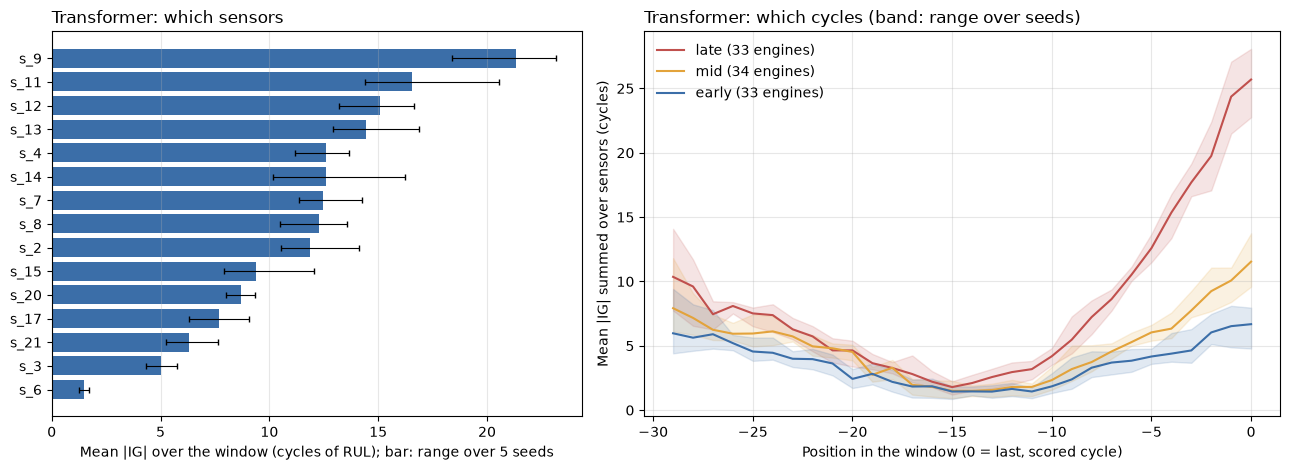

In [4]:
STAGE_COLOURS = {"late": "#c0504d", "mid": "#e3a33b", "early": "#3b6ea8"}
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
t = sensor_ig[sensor_ig.model == "Transformer"].set_index("sensor").loc[ranking.index]
ax.barh(range(len(t))[::-1], t["mean |IG|"], color="#3b6ea8",
        xerr=[t["mean |IG|"] - t["seed min"], t["seed max"] - t["mean |IG|"]], error_kw={"lw": 0.8, "capsize": 2})
ax.set_yticks(range(len(t))[::-1], t.index)
ax.set_xlabel("Mean |IG| over the window (cycles of RUL); bar: range over 5 seeds")
ax.set_title("Transformer: which sensors", loc="left")
ax.grid(axis="x", alpha=0.3)
for stage, colour in STAGE_COLOURS.items():
    s = time_ig[(time_ig.model == "Transformer") & (time_ig.stage == stage)].groupby("position")["mean |IG|"]
    m, lo, hi = s.mean(), s.min(), s.max()
    bx.plot(m.index, m, color=colour, label=f"{stage} ({int((stage_of == stage).sum())} engines)")
    bx.fill_between(m.index, lo, hi, color=colour, alpha=0.15)
bx.set_xlabel("Position in the window (0 = last, scored cycle)")
bx.set_ylabel("Mean |IG| summed over sensors (cycles)")
bx.set_title("Transformer: which cycles (band: range over seeds)", loc="left")
bx.legend(frameon=False)
bx.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "fd001_interpretability_ig.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Comparison with the Phase 1 SHAP ranking

Two references:

- **Phase 1** (`notebooks/phase1/03_ml_models.ipynb`): mean absolute SHAP for the uncapped Random Forest and XGBoost on engineered features, over 200 held-out training cycles. The notebook shows the top 12 features only, so the cell below reads those tables from its saved output and sums them by sensor. Sensors outside the top 12 count as 0.
- **The frozen #61 XGBoost on engineered features** (cap 125, the model scored in #71), refit with its chosen settings and explained with SHAP on the same 100 test engines at their last cycle. This compares like with like: the same engines and the same cap as the Transformer.

Engineered features are named `s_<n>_<statistic>_<window>`, so each is credited to its sensor. `cycle` is not a sensor. The sequence models never see it, so it is listed apart from the sensor ranking.

In [5]:
import shap
import run_ml_baselines as mlb


def sensor_of(feature):
    m = re.match(r"(s_\d+)", feature)
    return m.group(1) if m else feature


phase1 = nbformat.read(ROOT / "notebooks/phase1/03_ml_models.ipynb", as_version=4)
tables = [o["data"]["text/plain"] for c in phase1.cells if c.cell_type == "code" and "shap.TreeExplainer" in c.source
          for o in c.outputs if "text/plain" in o.get("data", {}) and "mean absolute SHAP" in o["data"]["text/plain"]]
assert len(tables) == 2, "expected the Random Forest and XGBoost SHAP tables"
phase1_shap = {}
for name, text in zip(("Phase 1 RF SHAP", "Phase 1 XGBoost SHAP"), tables):
    rows = [line.split() for line in text.splitlines()[1:] if line.strip()]
    s = pd.Series({f: float(v) for f, v in rows})
    phase1_shap[name] = s.groupby(sensor_of).sum()

ml_cv = json.loads((METRICS / "fd001_ml_capped_cv.json").read_text())["chosen"]
xgb_params = next(c["params"] for c in ml_cv if c["variant"] == "engineered" and c["model"] == "xgboost" and c["cap"] == "125")
from rul.data.labels import add_train_rul
labelled_train = add_train_rul(train)
xgb = mlb.final_model("engineered", "xgboost", xgb_params, 42)
xgb.fit(labelled_train.drop(columns="rul"), labelled_train["rul"].clip(upper=125))
features = xgb.named_steps["features"].transform(test).loc[last_rows.index]
saved_xgb = pd.read_csv(METRICS / "fd001_ml_capped_test_predictions.csv").sort_values("unit")["engineered_xgboost_cap125"]
assert np.allclose(xgb.named_steps["model"].predict(features), saved_xgb.to_numpy(), atol=1e-3), "refit differs from #71"
explanation = shap.TreeExplainer(xgb.named_steps["model"])(features)
xgb_shap = pd.Series(np.abs(explanation.values).mean(axis=0), index=features.columns)
test_shap = xgb_shap.groupby(sensor_of).sum()

compare = pd.DataFrame({
    "Transformer IG": ranking["Transformer"], "LSTM IG": ranking["LSTM"], "Temporal CNN IG": ranking["Temporal CNN"],
    "XGBoost SHAP (test, cap 125)": test_shap, **phase1_shap,
}).fillna(0.0)
others = compare.loc[[i for i in compare.index if not i.startswith("s_")]]
others = others[others.sum(axis=1) > 0]
compare = compare.loc[[i for i in compare.index if i.startswith("s_")]].sort_values("Transformer IG", ascending=False)
ranks = compare.rank(ascending=False).astype(int)
print("Contribution by sensor (cycles), sorted by the Transformer:")
display(compare.round(2))
print("Inputs that are not sensors:")
display(others.round(2))
top5 = {c: set(compare[c].nlargest(5).index) for c in compare}
agreement = pd.DataFrame({
    "Spearman with Transformer IG": {c: spearmanr(compare["Transformer IG"], compare[c])[0] for c in compare},
    "top-5 sensors shared with Transformer": {c: len(top5[c] & top5["Transformer IG"]) for c in compare},
    "top 5": {c: ", ".join(compare[c].nlargest(5).index) for c in compare},
})
display(agreement.round(2))
compare.round(4).to_csv(METRICS / "fd001_interpretability_sensors.csv")

Contribution by sensor (cycles), sorted by the Transformer:


,Transformer IG,LSTM IG,Temporal CNN IG,"XGBoost SHAP (test, cap 125)",Phase 1 RF SHAP,Phase 1 XGBoost SHAP
s_9,21.34,18.59,14.89,6.32,2.09,0.00
s_11,16.56,16.61,16.97,9.20,10.20,12.84
s_12,15.09,16.13,17.23,2.85,0.00,0.00
s_13,14.42,16.39,17.76,2.36,0.00,0.00
s_4,12.62,16.35,16.27,7.86,7.64,5.31
s_14,12.60,15.54,17.30,2.92,1.96,8.19
s_7,12.48,13.60,14.33,2.34,0.00,0.00
s_8,12.29,13.75,15.43,3.77,0.00,0.00
s_2,11.88,14.32,15.43,3.61,0.00,3.24
s_15,9.41,9.87,13.56,6.95,2.90,7.62


Inputs that are not sensors:


,Transformer IG,LSTM IG,Temporal CNN IG,"XGBoost SHAP (test, cap 125)",Phase 1 RF SHAP,Phase 1 XGBoost SHAP
cycle,0.0,0.0,0.0,4.55,29.15,22.19
op_1,0.0,0.0,0.0,0.00,0.00,0.00


,Spearman with Transformer IG,top-5 sensors shared with Transformer,top 5
Transformer IG,1.00,5,"s_9, s_11, s_12, s_13, s_4"
LSTM IG,0.97,5,"s_9, s_11, s_13, s_4, s_12"
Temporal CNN IG,0.74,4,"s_13, s_14, s_12, s_11, s_4"
"XGBoost SHAP (test, cap 125)",0.54,3,"s_11, s_4, s_15, s_9, s_8"
Phase 1 RF SHAP,0.23,2,"s_11, s_4, s_20, s_15, s_3"
Phase 1 XGBoost SHAP,0.09,2,"s_11, s_14, s_20, s_15, s_4"


## 4. Transformer attention and the Hybrid A gate

**Attention.** The Transformer has one encoder layer with 4 heads, and it averages its outputs over all 30 positions (mean pooling). The plot shows the attention each position *receives*, averaged over heads, query positions, engines and seeds. Uniform attention would be 1/30 per position.

**Gate.** Hybrid A's gate on every test cycle (not only the last), averaged over the gate's entries, against the cycle's true RUL, for the 5 seeds. #68 found it close to 0.5 at every stage in cross-validation.

Share of attention received by the last 5 of 30 cycles (uniform 0.17): {'early': 0.26, 'late': 0.24, 'mid': 0.26}


stage,late,mid,early
seed,,,
42,0.511,0.472,0.461
43,0.534,0.504,0.496
44,0.524,0.537,0.560
45,0.498,0.496,0.497
46,0.495,0.509,0.515


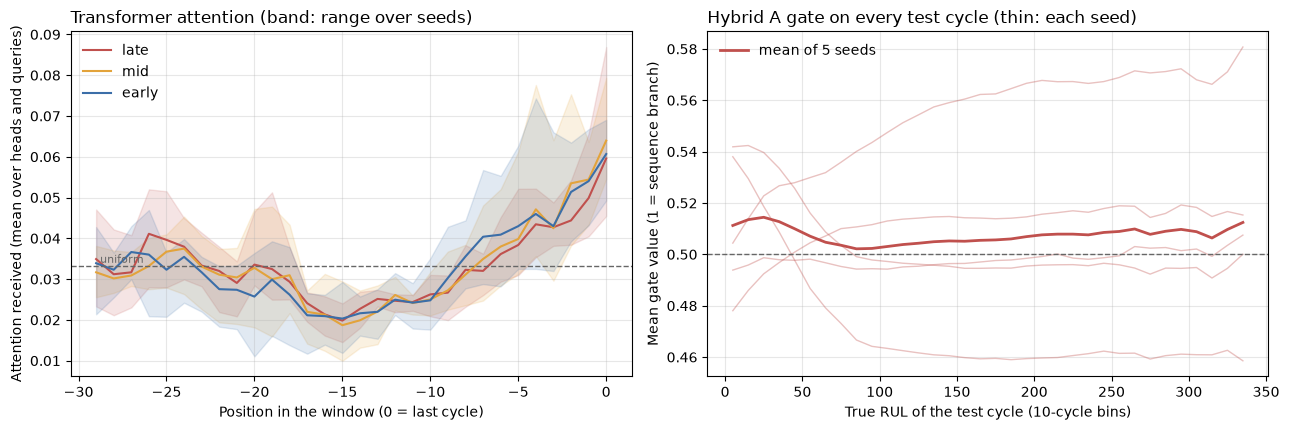

In [6]:
att_rows = []
for seed in SEEDS:
    trained = load("transformer", seed)
    (x,) = last_windows(trained)
    maps = trained.model.encoder.eval().attention(x)  # one layer: [engines, heads, query, key]
    received = maps[0].mean(dim=(1, 2)).numpy().astype(float)  # [engines, key]
    for stage in STAGES:
        for t, v in enumerate(received[stage_of == stage].mean(axis=0)):
            att_rows.append({"seed": seed, "stage": stage, "position": t - received.shape[1] + 1, "attention": v})
attention = pd.DataFrame(att_rows)
last5 = attention.assign(recent=attention.position >= -4).groupby(["stage", "recent"])["attention"].sum().unstack()
print("Share of attention received by the last 5 of 30 cycles (uniform 0.17):",
      (last5[True] / last5.sum(axis=1)).round(2).to_dict())

gate_rows = []
for seed in SEEDS:
    trained = load("hybrid_gated", seed)
    g = trained.outputs(test, trained.model.gate).mean(axis=1).astype(float)
    gate_rows.append(pd.DataFrame({"seed": seed, "rul": labelled.loc[test.index, "rul"].to_numpy(), "gate": g}))
gate = pd.concat(gate_rows)
gate["stage"] = pd.cut(gate["rul"], [0, 50, 100, np.inf], labels=list(STAGES)).astype(str)
gate_stage = gate.groupby(["seed", "stage"])["gate"].mean().unstack()[list(STAGES)]
display(gate_stage.round(3))
pd.concat([attention.assign(kind="attention"),
           gate.groupby(["seed", "stage"])["gate"].mean().reset_index().assign(kind="gate")]
          ).round(4).to_csv(METRICS / "fd001_interpretability_attention_gate.csv", index=False)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.4))
for stage, colour in STAGE_COLOURS.items():
    s = attention[attention.stage == stage].groupby("position")["attention"]
    ax.plot(s.mean().index, s.mean(), color=colour, label=stage)
    ax.fill_between(s.mean().index, s.min(), s.max(), color=colour, alpha=0.15)
ax.axhline(1 / 30, color="#666", ls="--", lw=1)
ax.text(-29, 1 / 30, " uniform", va="bottom", fontsize=8, color="#666")
ax.set_xlabel("Position in the window (0 = last cycle)")
ax.set_ylabel("Attention received (mean over heads and queries)")
ax.set_title("Transformer attention (band: range over seeds)", loc="left")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
bins = np.arange(0, gate["rul"].max() + 10, 10)
gate["bin"] = pd.cut(gate["rul"], bins, include_lowest=True)
curve = gate.groupby(["seed", "bin"], observed=True)["gate"].mean().unstack("seed")
mid = [b.mid for b in curve.index]
for seed in SEEDS:
    bx.plot(mid, curve[seed], color="#c0504d", alpha=0.35, lw=1)
bx.plot(mid, curve.mean(axis=1), color="#c0504d", lw=2, label="mean of 5 seeds")
bx.axhline(0.5, color="#666", ls="--", lw=1)
bx.set_xlabel("True RUL of the test cycle (10-cycle bins)")
bx.set_ylabel("Mean gate value (1 = sequence branch)")
bx.set_title("Hybrid A gate on every test cycle (thin: each seed)", loc="left")
bx.legend(frameon=False)
bx.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "fd001_interpretability_attention_gate.png", dpi=150, bbox_inches="tight")
plt.show()